<a href="https://colab.research.google.com/github/minhphu12-oc/gg-colab/blob/sklearn-project-for-machine-learning/project_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

link tải dataset : https://www.kaggle.com/code/buntyshah/insurance-fraud-claims-detection

# BƯỚC 1: ĐỌC DỮ LIỆU

1.1 gọi dữ liệu và đọc 5 dòng đầu

In [1]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report,make_scorer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv('insurance_claims.csv')
df.head(5)

,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported,_c39
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,YES,71610,6510,13020,52080,Saab,92x,2004,Y,NaN
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,?,5070,780,780,3510,Mercedes,E400,2007,Y,NaN
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,NO,34650,7700,3850,23100,Dodge,RAM,2007,N,NaN
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,...,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y,NaN
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,...,NO,6500,1300,650,4550,Accura,RSX,2009,N,NaN


In [3]:
df.shape

(1000, 40)

trong collison_type ( loại va chạm có những phần có dấu ? thì không phải là thiếu mà là không bị chấn thương nên sẽ chuyển nó về thành None )

phần authorities_contacted có những phần là NaN là bị thiếu nhưng đây là những chỗ cần điền dữ liệu nên chúng ta sẽ cần cách để điền lại vào những chỗ còn thiếu ( câu hỏi yes-no cũng tương tự )

1.2 đọc thông tin dữ liệu

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   months_as_customer           1000 non-null   int64  
 1   age                          1000 non-null   int64  
 2   policy_number                1000 non-null   int64  
 3   policy_bind_date             1000 non-null   object 
 4   policy_state                 1000 non-null   object 
 5   policy_csl                   1000 non-null   object 
 6   policy_deductable            1000 non-null   int64  
 7   policy_annual_premium        1000 non-null   float64
 8   umbrella_limit               1000 non-null   int64  
 9   insured_zip                  1000 non-null   int64  
 10  insured_sex                  1000 non-null   object 
 11  insured_education_level      1000 non-null   object 
 12  insured_occupation           1000 non-null   object 
 13  insured_hobbies    

1.3 tìm những chỗ dữ liệu thiếu cần phải điền missing value

In [5]:
print(df.isnull().sum())

months_as_customer                0
age                               0
policy_number                     0
policy_bind_date                  0
policy_state                      0
policy_csl                        0
policy_deductable                 0
policy_annual_premium             0
umbrella_limit                    0
insured_zip                       0
insured_sex                       0
insured_education_level           0
insured_occupation                0
insured_hobbies                   0
insured_relationship              0
capital-gains                     0
capital-loss                      0
incident_date                     0
incident_type                     0
collision_type                    0
incident_severity                 0
authorities_contacted            91
incident_state                    0
incident_city                     0
incident_location                 0
incident_hour_of_the_day          0
number_of_vehicles_involved       0
property_damage             

# Bước 2: Tiền xử lí dữ liệu

2.1 chuyển đổi data

In [6]:
import pandas as pd
import numpy as np

df = pd.read_csv("insurance_claims.csv")

data = df.copy()

data.drop(columns=["_c39"], inplace=True)

missing_cols = [
    "collision_type",
    "property_damage",
    "police_report_available"
]

for col in missing_cols:
    data[col] = data[col].replace("?", np.nan)

mask = data["incident_type"].isin([
    "Vehicle Theft",
    "Parked Car"
])

data.loc[mask, "collision_type"] = "Not applicable"

data["collision_type"] = data["collision_type"].fillna("Unknown")

data["property_damage"] = data["property_damage"].fillna("Unknown")
data["police_report_available"] = data["police_report_available"].fillna("Unknown")

In [7]:
data["umbrella_invalid"] = (
    data["umbrella_limit"] < 0
).astype(int)

data.loc[
    data["umbrella_limit"] < 0,
    "umbrella_limit"
] = np.nan

2.2 kiểm tra lại dữ liệu

In [8]:
df.head(5)

,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported,_c39
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,YES,71610,6510,13020,52080,Saab,92x,2004,Y,NaN
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,?,5070,780,780,3510,Mercedes,E400,2007,Y,NaN
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,NO,34650,7700,3850,23100,Dodge,RAM,2007,N,NaN
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,...,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y,NaN
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,...,NO,6500,1300,650,4550,Accura,RSX,2009,N,NaN


2.3 xử lí dữ liệu

In [9]:
data["fraud_reported"] = data["fraud_reported"].map({
    "N": 0,
    "Y": 1
})

x = data.drop(columns=["fraud_reported"])
y = data["fraud_reported"]

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

num_cols = x_train.select_dtypes(include=np.number).columns.tolist()

cat_cols = x_train.select_dtypes(include=["object"]).columns.tolist()

num_pipe = Pipeline([
    ("imputer", KNNImputer(n_neighbors = 19)),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

# Bước 3 : training model

3.1 train model cơ bản

Model: Random Forest
classification_report:
              precision    recall  f1-score   support

           0       0.76      0.97      0.85       151
           1       0.43      0.06      0.11        49

    accuracy                           0.75       200
   macro avg       0.60      0.52      0.48       200
weighted avg       0.68      0.75      0.67       200




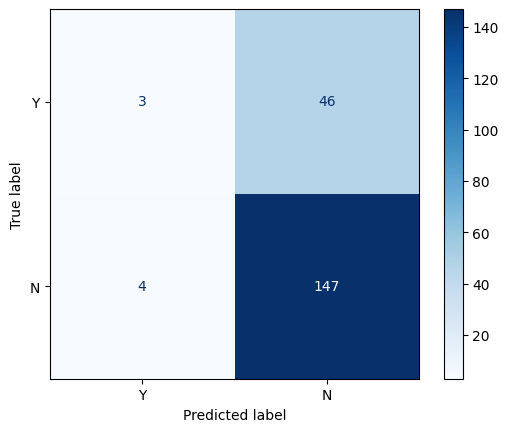

Model: Decision Tree
classification_report:
              precision    recall  f1-score   support

           0       0.86      0.86      0.86       151
           1       0.57      0.57      0.57        49

    accuracy                           0.79       200
   macro avg       0.72      0.72      0.72       200
weighted avg       0.79      0.79      0.79       200




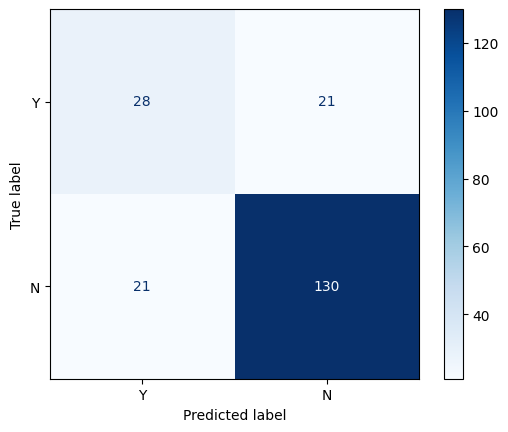

In [10]:
# gọi model
model = {"Random Forest": RandomForestClassifier(random_state=42), "Decision Tree": DecisionTreeClassifier(random_state=42)}
for i in model:
  pipeline = Pipeline([("preprocessor", preprocessor), ("model", model[i])])
  pipeline.fit(x_train, y_train)
  y_pred = pipeline.predict(x_test)

  print(f"Model: {i}")
  print(f"classification_report:")
  print(classification_report(y_test, y_pred))
  print()
  con = confusion_matrix(y_test, y_pred, labels=[1, 0])
  disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=["Y", "N"])
  disp.plot(cmap = "Blues")
  plt.show()

decision tree có vẻ đang học tốt hơn rf nhưng mà điểm của cả hai model vẫn quá kém . giờ thử gridsearch xem model có cải tiến hơn không

3.2 tuning

--- RANDOM FOREST ---
Best Params: {'model__bootstrap': True, 'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_split': 17, 'model__n_estimators': 250}

classification_report:
              precision    recall  f1-score   support

           0       0.92      0.86      0.89       151
           1       0.64      0.78      0.70        49

    accuracy                           0.84       200
   macro avg       0.78      0.82      0.80       200
weighted avg       0.85      0.84      0.84       200


F1-score (Y): 0.7037037037037037


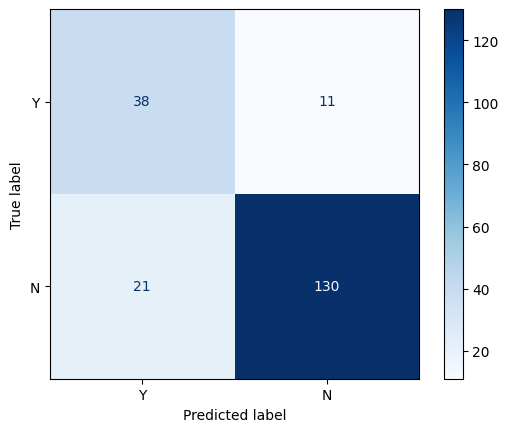


Top 10 Feature Importances:


,Feature,Importance
905,incident_severity_Major Damage,0.076377
816,insured_hobbies_chess,0.051564
906,incident_severity_Minor Damage,0.046406
13,total_claim_amount,0.041960
16,vehicle_claim,0.033783
817,insured_hobbies_cross-fit,0.032362
15,property_claim,0.030931
6,insured_zip,0.025241
14,injury_claim,0.024689
907,incident_severity_Total Loss,0.018292


In [11]:
from sklearn.metrics import make_scorer

f1_scorer = make_scorer(f1_score, pos_label=1)

# RANDOM FOREST
param_grid_rf = {
    "model__criterion" : ["entropy"],
    "model__n_estimators" : [207, 210, 213, 250],
    "model__max_depth" : [5],
    "model__min_samples_split": [13, 15, 17],
    "model__bootstrap" : [True]
}

st = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid_rf = GridSearchCV(
    estimator=Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(random_state=42, class_weight="balanced"))
    ]),
    param_grid=param_grid_rf,
    cv=st,
    scoring=f1_scorer,
    n_jobs=-1
)

grid_rf.fit(x_train, y_train)
predict = grid_rf.predict(x_test)

print("--- RANDOM FOREST ---")
print("Best Params:", grid_rf.best_params_)
print("\nclassification_report:")
print(classification_report(y_test, predict))
print()
print("F1-score (Y):", f1_score(y_test, predict, pos_label=1))
con = confusion_matrix(y_test, predict, labels=[1, 0])
disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=["Y", "N"])
disp.plot(cmap="Blues")
plt.show()

cate_encoder = grid_rf.best_estimator_.named_steps['preprocessor'].named_transformers_['cat'].named_steps['encoder']
encoded_cate_cols = cate_encoder.get_feature_names_out(cat_cols).tolist()
all_features = num_cols + encoded_cate_cols

best_rf_model = grid_rf.best_estimator_.named_steps['model']
importances = best_rf_model.feature_importances_

# Hiển thị Top 10 đặc trưng quan trọng nhất
feat_imp_df = pd.DataFrame({'Feature': all_features, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)
print("\nTop 10 Feature Importances:")
display(feat_imp_df.head(10))

Fitting 10 folds for each of 200 candidates, totalling 2000 fits
classification_report:
              precision    recall  f1-score   support

           0       0.95      0.84      0.89       151
           1       0.64      0.86      0.73        49

    accuracy                           0.84       200
   macro avg       0.79      0.85      0.81       200
weighted avg       0.87      0.84      0.85       200




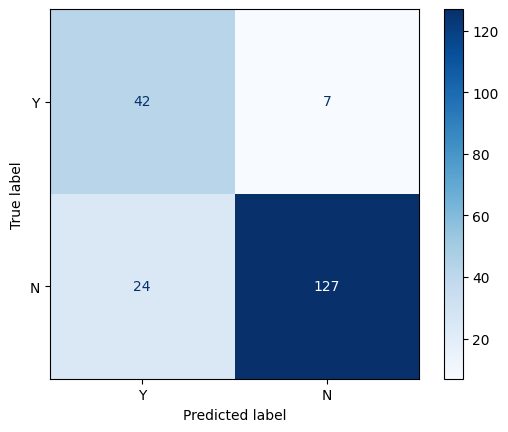

best param: {'model__splitter': 'random', 'model__min_samples_split': 30, 'model__min_samples_leaf': 15, 'model__max_features': None, 'model__max_depth': 3, 'model__criterion': 'log_loss', 'model__ccp_alpha': 0.0001}

Top 10 Feature Importances (Decision Tree):


,Feature,Importance
905,incident_severity_Major Damage,0.452306
816,insured_hobbies_chess,0.270445
817,insured_hobbies_cross-fit,0.250073
802,insured_occupation_handlers-cleaners,0.014230
828,insured_hobbies_sleeping,0.012946
1198,incident_location_3929 Oak Drive,0.000000
1197,incident_location_3929 Elm Ave,0.000000
1196,incident_location_3926 Rock Lane,0.000000
1195,incident_location_3925 Sky St,0.000000
1194,incident_location_3915 Embaracadero St,0.000000


In [12]:
st = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
f1_scorer = make_scorer(f1_score, pos_label=1)

# DECISION TREE
param_grid_dt = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__splitter": ["best", "random"],
    "model__max_depth": [3, 4, 5, 6, 7, 8, 10, 12, None],
    "model__min_samples_split": [2, 5, 10, 15, 20, 30, 40],
    "model__min_samples_leaf": [1, 2, 4, 5, 8, 10, 15, 20],
    "model__max_features": [None, "sqrt", "log2"],
    "model__ccp_alpha": [0.0, 0.0001]}

grid_dt = RandomizedSearchCV(estimator=Pipeline([("preprocessor", preprocessor),
                                           ("model", DecisionTreeClassifier(random_state=42, class_weight="balanced"))]),
                                            param_distributions = param_grid_dt, cv = st, n_iter = 200,
                                             scoring = f1_scorer, n_jobs=-1, verbose = 1, refit = True, random_state=42)
grid_dt.fit(x_train, y_train)
predict = grid_dt.predict(x_test)
print(f"classification_report:")
print(classification_report(y_test, predict))
print()
con = confusion_matrix(y_test, predict, labels=[1, 0])
disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=["Y", "N"])
disp.plot(cmap = "Blues")
plt.show()

best_dt_model = grid_dt.best_estimator_.named_steps['model']
importances_dt = best_dt_model.feature_importances_
print(f"best param: {grid_dt.best_params_}")
# Hiển thị Top 10 đặc trưng quan trọng nhất
feat_imp_dt_df = pd.DataFrame({'Feature': all_features, 'Importance': importances_dt})
feat_imp_dt_df = feat_imp_dt_df.sort_values(by='Importance', ascending=False)
print("\nTop 10 Feature Importances (Decision Tree):")
display(feat_imp_dt_df.head(10))

In [13]:
for name, grid_model in [("Random Forest", grid_rf), ("Decision Tree", grid_dt)]:
    f1 = f1_score(y_test, grid_model.predict(x_test), pos_label=1)
    prec = precision_score(y_test, grid_model.predict(x_test), pos_label=1, zero_division=0)
    rec = recall_score(y_test, grid_model.predict(x_test), pos_label=1)
    print(f"Model: {name}")
    print(f"F1-score (Y): {f1:.4f}")
    print(f"Precision (Y): {prec:.4f}")
    print(f"Recall (Y): {rec:.4f}")

Model: Random Forest
F1-score (Y): 0.7037
Precision (Y): 0.6441
Recall (Y): 0.7755
Model: Decision Tree
F1-score (Y): 0.7304
Precision (Y): 0.6364
Recall (Y): 0.8571


3.3 cải tiến model

ta nhận thấy một vấn đề là recall của model khá ổn sau khi tuning nhưng precision của model lại là cái kéo chỉ số f1 của model xuống rất nhiều. nên ta sẽ thử tăng threehold lên để giúp precision tăng lên xem model có cải thiện được đang kể chỉ số f1 không

In [14]:
# thử tăng threshold lên cho cả hai mô hình đã tuned
thresholds = [0.2, 0.3, 0.4, 0.5, 0.55, 0.60, 0.65, 0.70]

for name, grid_model in [("Random Forest", grid_rf), ("Decision Tree", grid_dt)]:
    print(f"=== THỬ NGHIỆM NGƯỠNG CHO {name.upper()} ===")
    # Lớp 1 tương ứng với nhãn số 1 (Y)
    y_idx = list(grid_model.classes_).index(1)
    y_probs = grid_model.predict_proba(x_test)[:, y_idx]

    for th in thresholds:
        y_pred_th = np.where(y_probs >= th, 1, 0)
        f1 = f1_score(y_test, y_pred_th, pos_label=1)
        prec = precision_score(y_test, y_pred_th, pos_label=1, zero_division=0)
        rec = recall_score(y_test, y_pred_th, pos_label=1)
        print(f"Ngưỡng: {th:.2f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1-score: {f1:.4f}")
    print("\n")

=== THỬ NGHIỆM NGƯỠNG CHO RANDOM FOREST ===
Ngưỡng: 0.20 | Precision: 0.2450 | Recall: 1.0000 | F1-score: 0.3936
Ngưỡng: 0.30 | Precision: 0.2475 | Recall: 1.0000 | F1-score: 0.3968
Ngưỡng: 0.40 | Precision: 0.2882 | Recall: 1.0000 | F1-score: 0.4475
Ngưỡng: 0.50 | Precision: 0.6441 | Recall: 0.7755 | F1-score: 0.7037
Ngưỡng: 0.55 | Precision: 0.5833 | Recall: 0.2857 | F1-score: 0.3836
Ngưỡng: 0.60 | Precision: 0.0000 | Recall: 0.0000 | F1-score: 0.0000
Ngưỡng: 0.65 | Precision: 0.0000 | Recall: 0.0000 | F1-score: 0.0000
Ngưỡng: 0.70 | Precision: 0.0000 | Recall: 0.0000 | F1-score: 0.0000


=== THỬ NGHIỆM NGƯỠNG CHO DECISION TREE ===
Ngưỡng: 0.20 | Precision: 0.6364 | Recall: 0.8571 | F1-score: 0.7304
Ngưỡng: 0.30 | Precision: 0.6364 | Recall: 0.8571 | F1-score: 0.7304
Ngưỡng: 0.40 | Precision: 0.6364 | Recall: 0.8571 | F1-score: 0.7304
Ngưỡng: 0.50 | Precision: 0.6364 | Recall: 0.8571 | F1-score: 0.7304
Ngưỡng: 0.55 | Precision: 0.6290 | Recall: 0.7959 | F1-score: 0.7027
Ngưỡng: 0.60 

qua hai model ta thấy được 2 data quan trọng nhất với model để học là :


*   incident_severity_Major Damage
*   insured_hobbies

ta thử tạo tệp dữ liệu chỉ có 2 dữ liệu đó để xem model học có tốt hơn không



In [15]:
df1 = df[["incident_severity", "insured_hobbies"]].copy()

df1["fraud_reported"] = df["fraud_reported"]

display(df1.head(5))

,incident_severity,insured_hobbies,fraud_reported
0,Major Damage,sleeping,Y
1,Minor Damage,reading,Y
2,Minor Damage,board-games,N
3,Major Damage,board-games,Y
4,Minor Damage,board-games,N


Model: Random Forest
classification_report:
              precision    recall  f1-score   support

           0       0.94      0.82      0.88       145
           1       0.64      0.85      0.73        55

    accuracy                           0.83       200
   macro avg       0.79      0.84      0.80       200
weighted avg       0.86      0.83      0.84       200




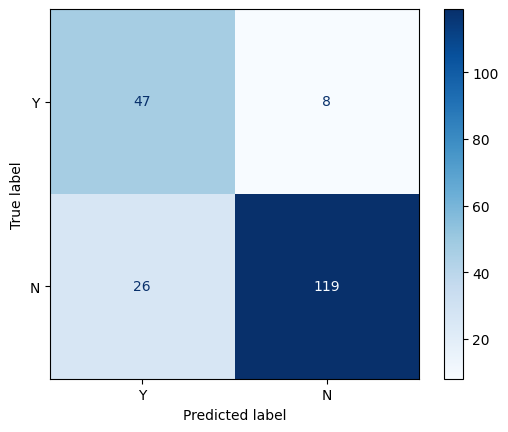


F1-score (Y): 0.7344
Model: Decision Tree
classification_report:
              precision    recall  f1-score   support

           0       0.94      0.82      0.88       145
           1       0.65      0.87      0.74        55

    accuracy                           0.83       200
   macro avg       0.80      0.85      0.81       200
weighted avg       0.86      0.83      0.84       200




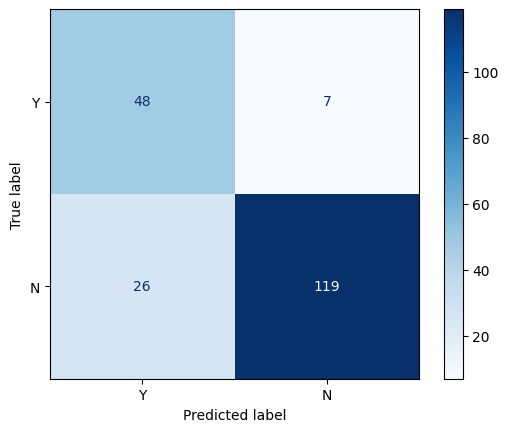


F1-score (Y): 0.7442


In [16]:
x = df1.drop(columns=['fraud_reported'])
y = df1['fraud_reported'].map({"N": 0, "Y": 1})
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

categorical_cols_df1 = ['incident_severity', 'insured_hobbies']
pate_transformer_df1 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor_df1 = ColumnTransformer([
    ("cate", pate_transformer_df1, categorical_cols_df1)
])

for name, grid_model in [("Random Forest", grid_rf), ("Decision Tree", grid_dt)]:
    pipeline = Pipeline([
        ("preprocessor", preprocessor_df1),
        ("model", grid_model.best_estimator_.named_steps['model'])
    ])
    pipeline.fit(x_train, y_train)
    y_pred = pipeline.predict(x_test)

    print(f"Model: {name}")
    print(f"classification_report:")
    print(classification_report(y_test, y_pred))
    print()
    con = confusion_matrix(y_test, y_pred, labels=[1, 0])
    disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=["Y", "N"])
    disp.plot(cmap = "Blues")
    plt.show()
    print()
    f1 = f1_score(y_test, y_pred, pos_label=1)
    print(f"F1-score (Y): {f1:.4f}")

In [17]:
import pandas as pd

data_comparison = [
    {
        "Model": "Random Forest",
        "Metric": "Precision (Y)",
        "Old": 0.43,
        "New": 0.6441
    },
    {
        "Model": "Random Forest",
        "Metric": "Recall (Y)",
        "Old": 0.06,
        "New": 0.7755
    },
    {
        "Model": "Random Forest",
        "Metric": "F1-score (Y)",
        "Old": 0.11,
        "New": 0.7037
    },
    {
        "Model": "Decision Tree",
        "Metric": "Precision (Y)",
        "Old": 0.56,
        "New": 0.6364
    },
    {
        "Model": "Decision Tree",
        "Metric": "Recall (Y)",
        "Old": 0.55,
        "New": 0.8571
    },
    {
        "Model": "Decision Tree",
        "Metric": "F1-score (Y)",
        "Old": 0.56,
        "New": 0.7304
    }
]

# Tạo DataFrame
compare_df = pd.DataFrame(data_comparison)
compare_df["Chênh lệch"] = compare_df["New"] - compare_df["Old"]

def highlight_diff(val):
    if val > 0:
        return 'color: green; font-weight: bold;'
    elif val < 0:
        return 'color: red; font-weight: bold;'
    else:
        return 'color: gray;'

styled_table = compare_df.style.format({
    'Old': '{:.4f}',
    'New': '{:.4f}',
    'Chênh lệch': '{:+.4f}'
}).map(highlight_diff, subset=['Chênh lệch'])

# Hiển thị bảng so sánh
display(styled_table)

,Model,Metric,Old,New,Chênh lệch
0,Random Forest,Precision (Y),0.4300,0.6441,+0.2141
1,Random Forest,Recall (Y),0.0600,0.7755,+0.7155
2,Random Forest,F1-score (Y),0.1100,0.7037,+0.5937
3,Decision Tree,Precision (Y),0.5600,0.6364,+0.0764
4,Decision Tree,Recall (Y),0.5500,0.8571,+0.3071
5,Decision Tree,F1-score (Y),0.5600,0.7304,+0.1704


ta có thể thấy được model cải tiến rất đáng kể khi trước học 40 feature mà độ dự đoán còn kém hơn việc học 2 feature quan trọng nhất nhưng tăng khả năng dự đoán

giờ ta thử thêm một cột feature xem model có cải tiến nữa không ?

In [18]:
df2 = df[["incident_severity", "insured_hobbies","vehicle_claim"]].copy()

df2["fraud_reported"] = df["fraud_reported"]

display(df2.head(5))

,incident_severity,insured_hobbies,vehicle_claim,fraud_reported
0,Major Damage,sleeping,52080,Y
1,Minor Damage,reading,3510,Y
2,Minor Damage,board-games,23100,N
3,Major Damage,board-games,50720,Y
4,Minor Damage,board-games,4550,N


Model: Random Forest
classification_report:
              precision    recall  f1-score   support

           0       0.94      0.82      0.88       145
           1       0.64      0.85      0.73        55

    accuracy                           0.83       200
   macro avg       0.79      0.84      0.80       200
weighted avg       0.86      0.83      0.84       200




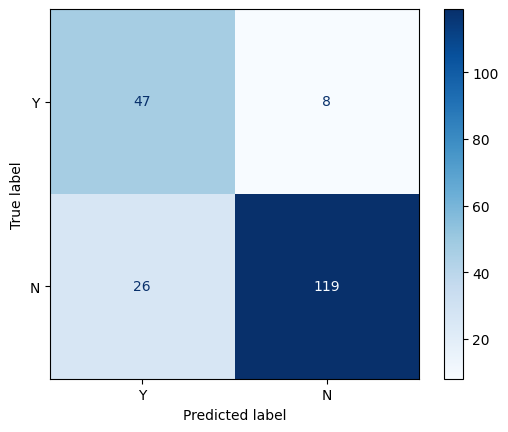


F1-score (Y): 0.7344
Model: Decision Tree
classification_report:
              precision    recall  f1-score   support

           0       0.94      0.82      0.88       145
           1       0.65      0.87      0.74        55

    accuracy                           0.83       200
   macro avg       0.80      0.85      0.81       200
weighted avg       0.86      0.83      0.84       200




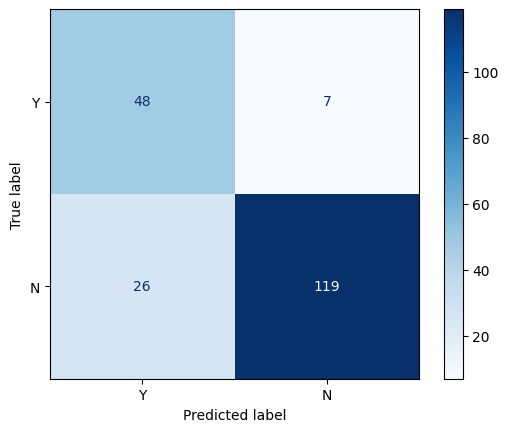


F1-score (Y): 0.7442


In [19]:
x = df2.drop(columns=['fraud_reported'])
y = df2['fraud_reported'].map({"N": 0, "Y": 1})
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

categorical_cols_df2 = ['incident_severity', 'insured_hobbies','vehicle_claim']
pate_transformer_df2 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor_df2 = ColumnTransformer([
    ("cate", pate_transformer_df2, categorical_cols_df2)
])

for name, grid_model in [("Random Forest", grid_rf), ("Decision Tree", grid_dt)]:
    pipeline = Pipeline([
        ("preprocessor", preprocessor_df2),
        ("model", grid_model.best_estimator_.named_steps['model'])
    ])
    pipeline.fit(x_train, y_train)
    y_pred = pipeline.predict(x_test)

    print(f"Model: {name}")
    print(f"classification_report:")
    print(classification_report(y_test, y_pred))
    print()
    con = confusion_matrix(y_test, y_pred, labels=[1, 0])
    disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=["Y", "N"])
    disp.plot(cmap = "Blues")
    plt.show()
    print()
    f1 = f1_score(y_test, y_pred, pos_label=1)
    print(f"F1-score (Y): {f1:.4f}")

In [20]:
import pandas as pd

data_compare = [
    {
        "Model": "Random Forest",
        "Metric": "Precision (Y)",
        "df1 (2 features)": 0.6400,
        "df2 (3 features)": 0.6400
    },
    {
        "Model": "Random Forest",
        "Metric": "Recall (Y)",
        "df1 (2 features)": 0.8500,
        "df2 (3 features)": 0.8500
    },
    {
        "Model": "Random Forest",
        "Metric": "F1-score (Y)",
        "df1 (2 features)": 0.7300,
        "df2 (3 features)": 0.7300
    },
    {
        "Model": "Decision Tree",
        "Metric": "Precision (Y)",
        "df1 (2 features)": 0.6500,
        "df2 (3 features)": 0.6500
    },
    {
        "Model": "Decision Tree",
        "Metric": "Recall (Y)",
        "df1 (2 features)": 0.8700,
        "df2 (3 features)": 0.8700
    },
    {
        "Model": "Decision Tree",
        "Metric": "F1-score (Y)",
        "df1 (2 features)": 0.7400,
        "df2 (3 features)": 0.7400
    }
]

# Tạo DataFrame
df_compare_models = pd.DataFrame(data_compare)
df_compare_models["Chênh lệch"] = df_compare_models["df2 (3 features)"] - df_compare_models["df1 (2 features)"]

def highlight_diff(val):
    if val > 0:
        return 'color: green; font-weight: bold;'
    elif val < 0:
        return 'color: red; font-weight: bold;'
    else:
        return 'color: gray;'

styled_table_df1_df2 = df_compare_models.style.format({
    'df1 (2 features)': '{:.4f}',
    'df2 (3 features)': '{:.4f}',
    'Chênh lệch': '{:+.4f}'
}).map(highlight_diff, subset=['Chênh lệch'])

display(styled_table_df1_df2)

,Model,Metric,df1 (2 features),df2 (3 features),Chênh lệch
0,Random Forest,Precision (Y),0.6400,0.6400,+0.0000
1,Random Forest,Recall (Y),0.8500,0.8500,+0.0000
2,Random Forest,F1-score (Y),0.7300,0.7300,+0.0000
3,Decision Tree,Precision (Y),0.6500,0.6500,+0.0000
4,Decision Tree,Recall (Y),0.8700,0.8700,+0.0000
5,Decision Tree,F1-score (Y),0.7400,0.7400,+0.0000


# Bước 4: Visualize cây quyết định

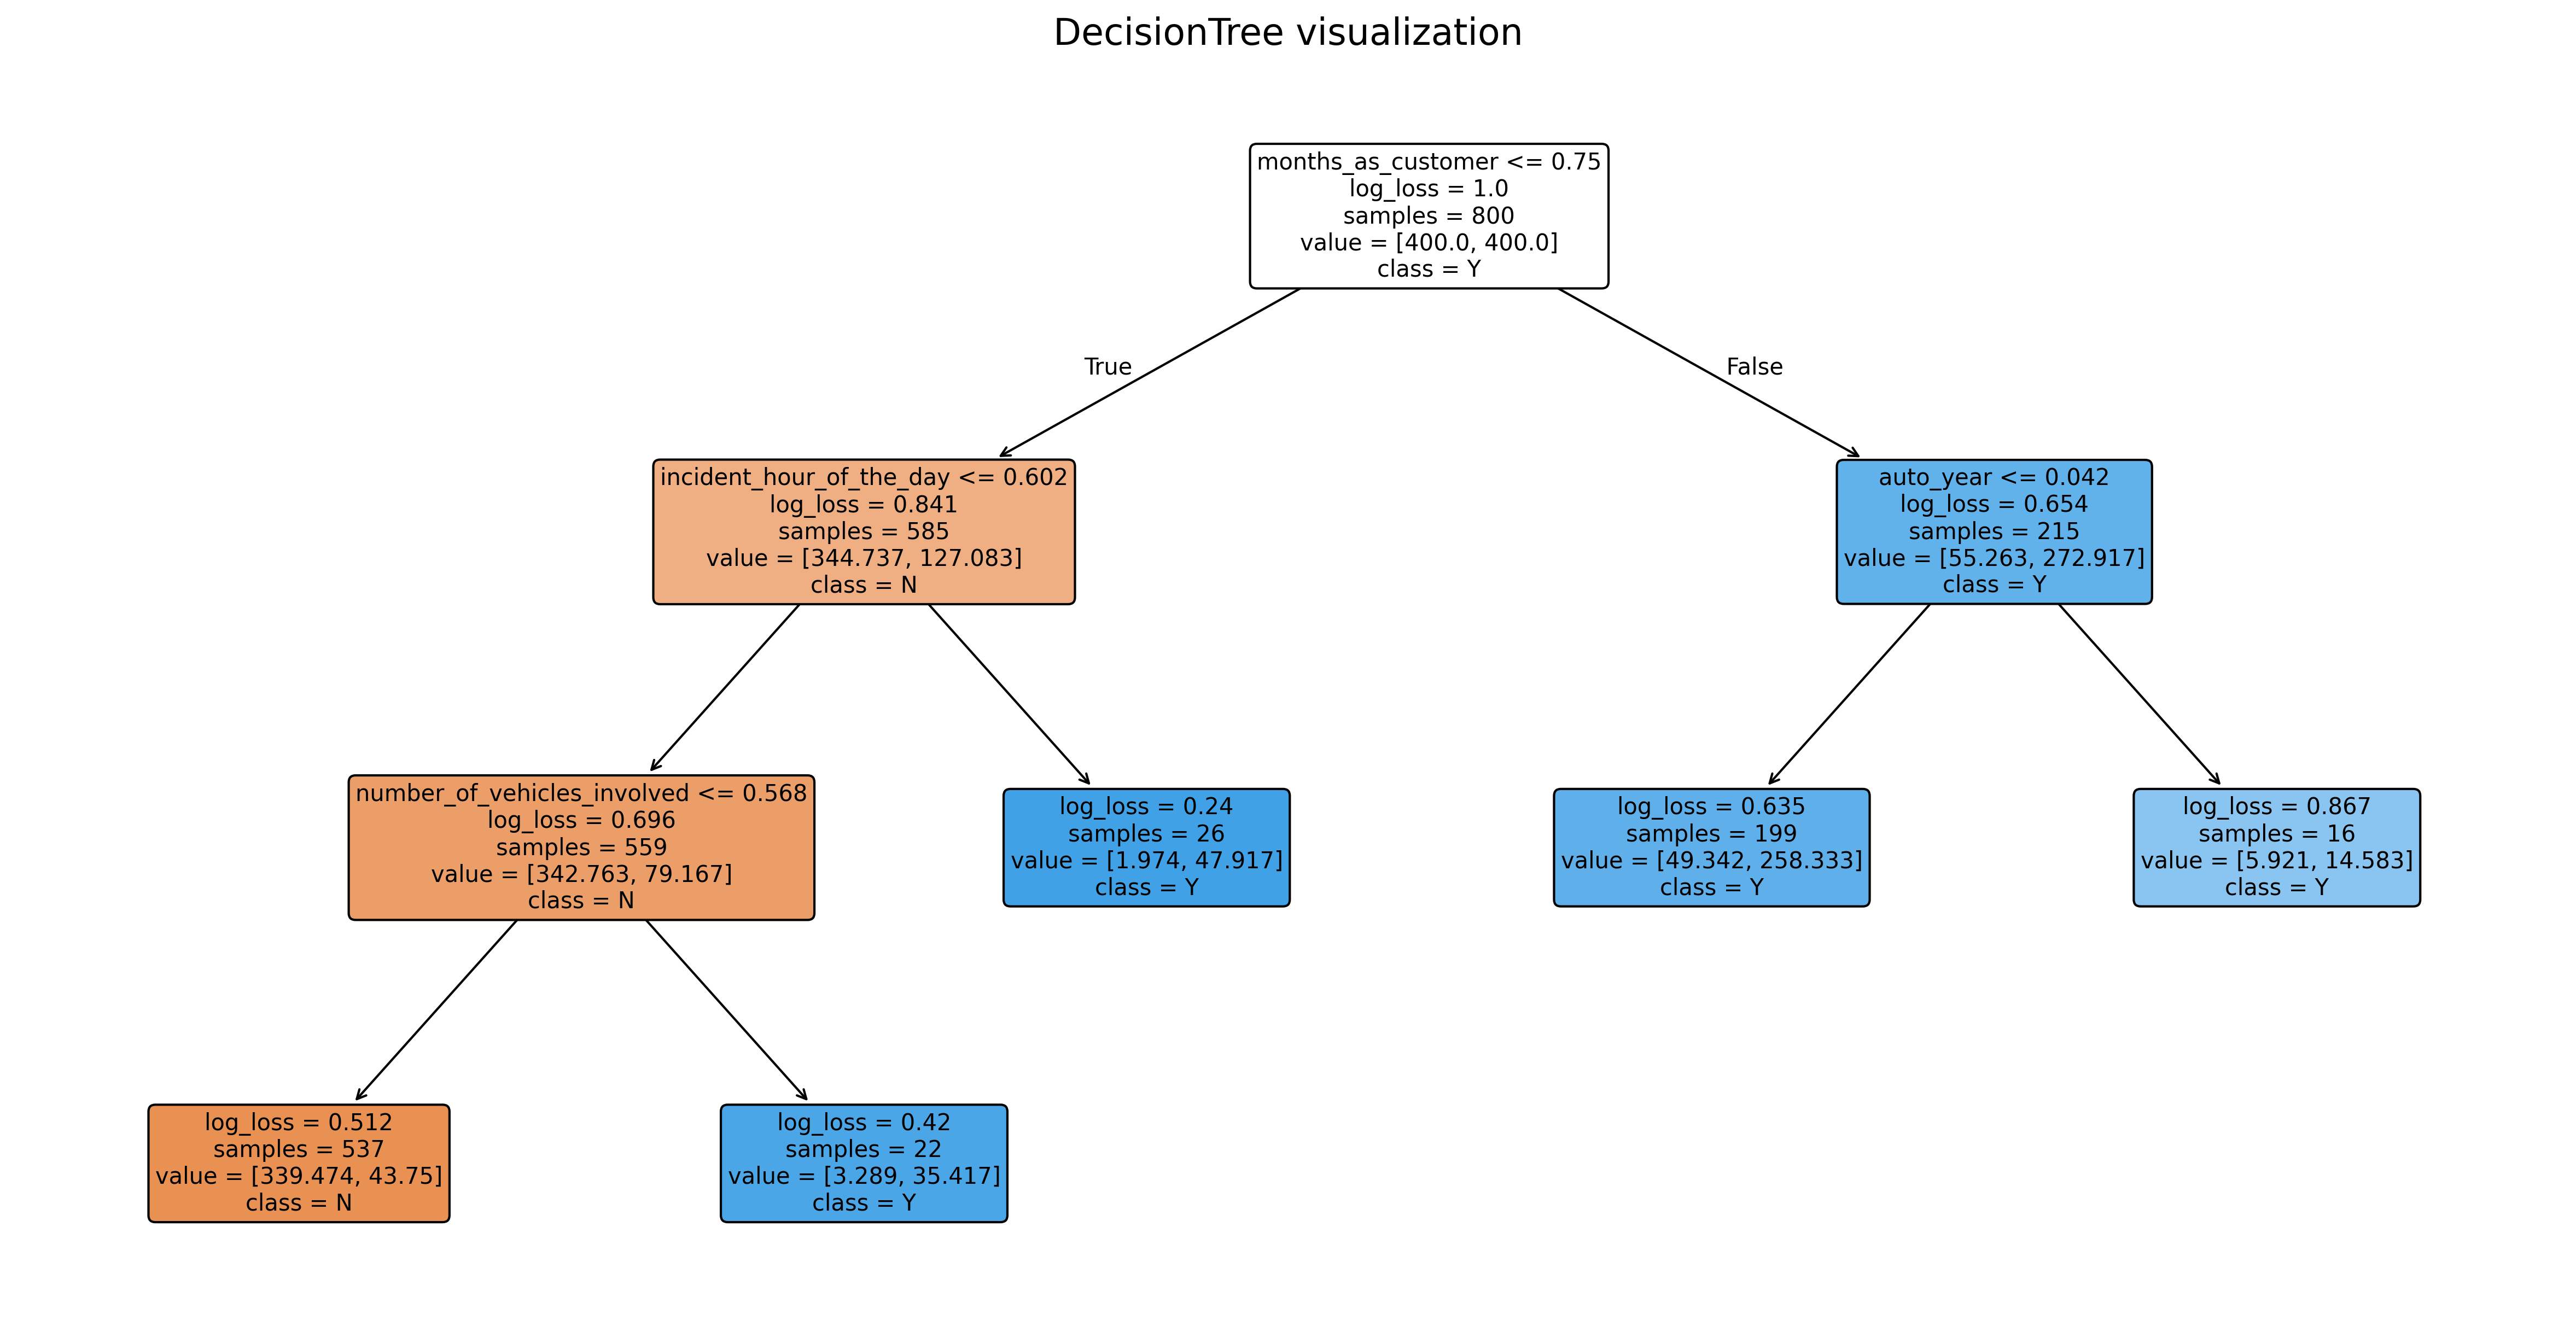

In [21]:
from sklearn.tree import plot_tree

# Lấy mô hình Decision Tree đã được fit tốt nhất từ Grid Search
best_dt = grid_dt.best_estimator_.named_steps['model']

# Lấy danh sách tên các đặc trưng sau khi qua bộ tiền xử lý One-Hot Encoder
feature_names = all_features

# Vẽ cây quyết định
fig, ax = plt.subplots(figsize=(20, 10), dpi=300)
plot_tree(
    best_dt,
    max_depth=5,
    feature_names=feature_names,
    class_names=['N', 'Y'],
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax,
)
plt.title("DecisionTree visualization", fontsize=16)
plt.show()

# kết luận:
như vậy sau khi tinh chỉnh dữ liệu, chọn lọc feature quan trọng và điều chỉnh các thông số của cây, ta đã thiết lập được model đơn giản nhất và hiệu quả nhất chỉ với 2-3 feature quan trọng!!!

bổ sung

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Classification Report:
              precision    recall  f1-score   support

   Non-Fraud       0.95      0.84      0.89       151
       Fraud       0.64      0.86      0.73        49

    accuracy                           0.84       200
   macro avg       0.79      0.85      0.81       200
weighted avg       0.87      0.84      0.85       200



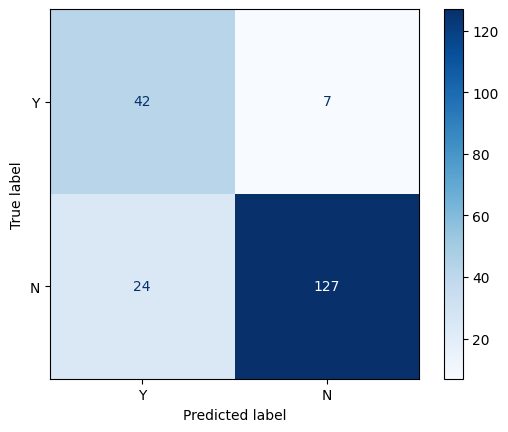

F1-score (Fraud): 0.7304
Best CV F1-score: 0.7557
Best params: {'model__splitter': 'random', 'model__min_samples_split': 20, 'model__min_samples_leaf': 8, 'model__max_depth': 6, 'model__criterion': 'entropy', 'model__ccp_alpha': 0.0001, 'kn__k': 10}


In [26]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
data_clean = df.copy()
data_clean.drop(columns=["_c39"], errors="ignore", inplace=True)

missing_cols = [
    "collision_type",
    "property_damage",
    "police_report_available"
]

for col in missing_cols:
    data_clean[col] = data_clean[col].replace("?", np.nan)

mask = data_clean["incident_type"].isin([
    "Vehicle Theft", "Parked Car"
])

data_clean.loc[mask, "collision_type"] = "Not applicable"

data_clean["collision_type"] = data_clean["collision_type"].fillna("Unknown")
data_clean["property_damage"] = data_clean["property_damage"].fillna("Unknown")
data_clean["police_report_available"] = data_clean["police_report_available"].fillna("Unknown")

data_clean.loc[
    data_clean["umbrella_limit"] < 0,
    "umbrella_limit"
] = np.nan

data_clean["fraud_reported"] = data_clean["fraud_reported"].map({
    "N": 0,
    "Y": 1
})

x = data_clean.drop(columns=["fraud_reported"])
y = data_clean["fraud_reported"]

cols_to_drop = [
    "policy_bind_date",
    "incident_date",
    "incident_location",
    "policy_number",
    "insured_zip",
    "umbrella_invalid"
]

x = x.drop(columns=cols_to_drop, errors="ignore")

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

local_num_cols = x_train.select_dtypes(include=np.number).columns.tolist()
local_cat_cols = x_train.select_dtypes(include=["object"]).columns.tolist()

local_num_pipe = Pipeline([
    ("imputer", KNNImputer(n_neighbors=19)),
    ("scaler", StandardScaler())
])

local_cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

local_preprocessor = ColumnTransformer([
    ("num", local_num_pipe, local_num_cols),
    ("cat", local_cat_pipe, local_cat_cols)
])

pipeline = ImbPipeline([
    ("preprocessor", local_preprocessor),
    ("kn", SelectKBest(score_func=f_classif)),
    ("smote", SMOTETomek(
        random_state=42,
        smote=SMOTE(k_neighbors=10, random_state=42)
    )),
    ("model", DecisionTreeClassifier(random_state=42))
])

param_grid = {
    "model__splitter": ["random", "best"],
    "model__min_samples_split": [15, 20],
    "model__min_samples_leaf": [8, 10],
    "model__max_depth": [4, 5, 6],
    "model__criterion": ["log_loss", "entropy"],
    "model__ccp_alpha": [0.0001],
    "kn__k": [10, 20, 30, 40, 50, "all"]
}

st = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_grid,
    n_iter=30,
    cv=st,
    scoring=f1_scorer,
    n_jobs=-1,
    verbose=1,
    refit=True,
    random_state=42,
    error_score="raise"
)

grid.fit(x_train, y_train)

predict = grid.predict(x_test)

print("Classification Report:")
print(classification_report(
    y_test,
    predict,
    target_names=["Non-Fraud", "Fraud"]
))

cm = confusion_matrix(y_test, predict, labels=[1, 0])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Y", "N"]
)

disp.plot(cmap="Blues")
plt.show()

print(f"F1-score (Fraud): {f1_score(y_test, predict, pos_label=1):.4f}")
print(f"Best CV F1-score: {grid.best_score_:.4f}")
print(f"Best params: {grid.best_params_}")


,K,Threshold,Precision (Y),Recall (Y),F1-score (Y)
7,4,0.200000,0.720000,0.900000,0.800000
15,6,0.300000,0.720000,0.900000,0.800000
13,4,0.800000,0.720000,0.900000,0.800000
12,4,0.700000,0.720000,0.900000,0.800000
11,4,0.600000,0.720000,0.900000,0.800000
10,4,0.500000,0.720000,0.900000,0.800000
9,4,0.400000,0.720000,0.900000,0.800000
8,4,0.300000,0.720000,0.900000,0.800000
20,6,0.800000,0.720000,0.900000,0.800000
17,6,0.500000,0.720000,0.900000,0.800000


Best K: 4
Best Threshold: 0.2
Validation F1: 0.8

Final Test Report:
              precision    recall  f1-score   support

   Non-Fraud       0.95      0.84      0.89       151
       Fraud       0.64      0.86      0.73        49

    accuracy                           0.84       200
   macro avg       0.79      0.85      0.81       200
weighted avg       0.87      0.84      0.85       200



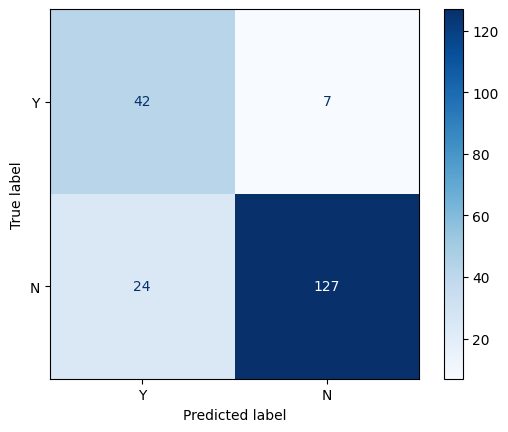

Test F1 (Fraud): 0.7304347826086957


In [31]:
k_comparison = []

k_values = [2, 4, 6, 8, 10, 12, 14, 16]
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
x_fit, x_val, y_fit, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42)
num_cols = x_fit.select_dtypes(include=np.number).columns.tolist()
cat_cols = x_fit.select_dtypes(include=["object"]).columns.tolist()
num_pipe = Pipeline([
    ("imputer", KNNImputer(n_neighbors=19)),
    ("scaler", StandardScaler())
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])
for k_val in k_values:

    pipe_test = ImbPipeline([
        ("preprocessor", preprocessor),
        ("kn", SelectKBest(score_func=f_classif, k=k_val)),
        ("smote", SMOTETomek(
            random_state=42,
            smote=SMOTE(k_neighbors=10, random_state=42)
        )),
        ("model", DecisionTreeClassifier(
            splitter="random",
            min_samples_split=15,
            min_samples_leaf=10,
            max_depth=6,
            criterion="entropy",
            ccp_alpha=0.0001,
            random_state=42
        ))
    ])
    pipe_test.fit(x_fit, y_fit)

    y_proba = pipe_test.predict_proba(x_val)
    pos_idx = list(pipe_test.named_steps["model"].classes_).index(1)

    y_pos_proba = y_proba[:, pos_idx]

    for th in thresholds:

        y_pred = (y_pos_proba >= th).astype(int)

        f1 = f1_score(y_val, y_pred, pos_label=1, zero_division=0)
        prec = precision_score(y_val, y_pred, pos_label=1, zero_division=0)
        rec = recall_score(y_val, y_pred, pos_label=1, zero_division=0)

        k_comparison.append({
            "K": k_val,
            "Threshold": th,
            "Precision (Y)": prec,
            "Recall (Y)": rec,
            "F1-score (Y)": f1
        })

table = pd.DataFrame(k_comparison)

display(
    table.sort_values("F1-score (Y)", ascending=False)
    .style.highlight_max(
        subset=["Precision (Y)", "Recall (Y)", "F1-score (Y)"],
        color="green"
    )
)

best_row = table.loc[table["F1-score (Y)"].idxmax()]

best_k = int(best_row["K"])
best_th = float(best_row["Threshold"])

print("Best K:", best_k)
print("Best Threshold:", best_th)
print("Validation F1:", best_row["F1-score (Y)"])

final_model = ImbPipeline([
    ("preprocessor", preprocessor),
    ("kn", SelectKBest(score_func=f_classif, k=best_k)),
    ("smote", SMOTETomek(
        random_state=42,
        smote=SMOTE(k_neighbors=10, random_state=42)
    )),
    ("model", DecisionTreeClassifier(
        splitter="random",
        min_samples_split=15,
        min_samples_leaf=10,
        max_depth=6,
        criterion="entropy",
        ccp_alpha=0.0001,
        random_state=42
    ))
])

final_model.fit(x_train, y_train)

test_proba = final_model.predict_proba(x_test)
pos_idx = list(final_model.named_steps["model"].classes_).index(1)

test_pred = (
    test_proba[:, pos_idx] >= best_th
).astype(int)

print("\nFinal Test Report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Non-Fraud", "Fraud"],
    zero_division=0
))

cm = confusion_matrix(y_test, test_pred, labels=[1, 0])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Y", "N"]
)

disp.plot(cmap="Blues")
plt.show()

print(
    "Test F1 (Fraud):",
    f1_score(y_test, test_pred, pos_label=1)
)


### Bổ sung

Fitting 5 folds for each of 40 candidates, totalling 200 fits
=== KẾT QUẢ RANDOM FOREST SAU KHI TỐI ƯU ===
              precision    recall  f1-score   support

   Non-Fraud       0.95      0.84      0.89       151
       Fraud       0.64      0.86      0.73        49

    accuracy                           0.84       200
   macro avg       0.79      0.85      0.81       200
weighted avg       0.87      0.84      0.85       200

Best CV F1-score: 0.7557
Test F1-score (Fraud): 0.7304
Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 15, 'model__max_depth': 4, 'model__criterion': 'gini', 'kn__k': 4}


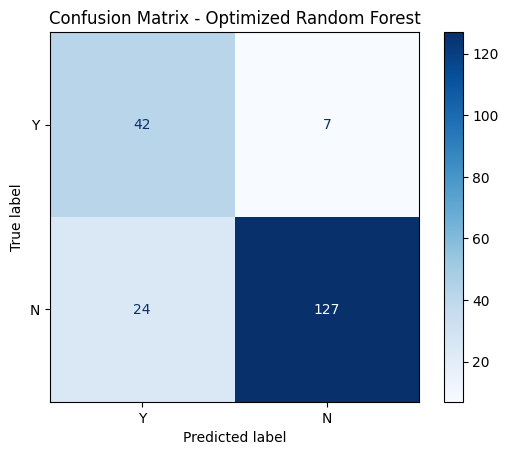

In [33]:
from imblearn.pipeline import Pipeline as imbpipeline
rf_pipeline = imbpipeline([
    ("preprocessor", local_preprocessor),
    ("kn", SelectKBest(score_func=f_classif)),
    ("smote", SMOTETomek(
        random_state=42,
        smote=SMOTE(k_neighbors=10, random_state=42)
    )),
    ("model", RandomForestClassifier(
        random_state=42
    ))
])

rf_param_grid = {
    "kn__k": [2, 4, 6, 8, 10, 12],
    "model__criterion": ["entropy", "gini"],
    "model__n_estimators": [100, 200, 250],
    "model__max_depth": [4, 5, 6],
    "model__min_samples_split": [15, 17, 20]
}

grid_rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_grid,
    n_iter=40,
    cv=st,
    scoring=f1_scorer,
    n_jobs=-1,
    verbose=1,
    refit=True,
    random_state=42,
    error_score="raise"
)

grid_rf_search.fit(x_train, y_train)

rf_predict = grid_rf_search.predict(x_test)

print("=== KẾT QUẢ RANDOM FOREST SAU KHI TỐI ƯU ===")

print(classification_report(
    y_test,
    rf_predict,
    target_names=["Non-Fraud", "Fraud"],
    zero_division=0
))

print(
    f"Best CV F1-score: {grid_rf_search.best_score_:.4f}"
)

print(
    f"Test F1-score (Fraud): "
    f"{f1_score(y_test, rf_predict, pos_label=1):.4f}"
)

print(f"Best parameters: {grid_rf_search.best_params_}")

cm_rf = confusion_matrix(
    y_test,
    rf_predict,
    labels=[1, 0]
)

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Y", "N"]
)

disp_rf.plot(cmap="Blues")
plt.title("Confusion Matrix - Optimized Random Forest")
plt.show()


Tiếp theo, chúng ta sẽ khảo sát sự thay đổi của các chỉ số hiệu năng (Precision, Recall, F1-score) khi thay đổi đồng thời số lượng đặc trưng ($k$) và ngưỡng quyết định (Threshold) trên mô hình Random Forest tốt nhất vừa tìm được.

In [41]:
rf_k_comparison = []

k_values = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
thresholds = [0.6, 0.61, 0.62, 0.63, 0.64, 0.65, 0.66, 0.67, 0.68]
best_rf_params = grid_rf_search.best_params_

for k_val in k_values:

    pipe_rf_eval = imbpipeline([
        ("preprocessor", local_preprocessor),
        ("kn", SelectKBest(score_func=f_classif, k=k_val)),
        ("smote", SMOTETomek(
            random_state=42,
            smote=SMOTE(k_neighbors=10, random_state=42)
        )),
        ("model", RandomForestClassifier(
            n_estimators=best_rf_params["model__n_estimators"],
            max_depth=best_rf_params["model__max_depth"],
            min_samples_split=best_rf_params["model__min_samples_split"],
            criterion=best_rf_params["model__criterion"],
            random_state=42,
            class_weight="balanced"
        ))
    ])

    pipe_rf_eval.fit(x_fit, y_fit)

    y_proba_rf = pipe_rf_eval.predict_proba(x_val)

    pos_idx = list(
        pipe_rf_eval.named_steps["model"].classes_
    ).index(1)

    y_pos_proba_rf = y_proba_rf[:, pos_idx]

    for th in thresholds:

        y_pred_th = (y_pos_proba_rf >= th).astype(int)

        f1 = f1_score(y_val, y_pred_th, pos_label=1, zero_division=0)
        prec = precision_score(y_val, y_pred_th, pos_label=1, zero_division=0)
        rec = recall_score(y_val, y_pred_th, pos_label=1, zero_division=0)

        rf_k_comparison.append({
            "K": k_val,
            "Threshold": th,
            "Precision (Y)": prec,
            "Recall (Y)": rec,
            "F1-score (Y)": f1
        })

rf_table = pd.DataFrame(rf_k_comparison)

rf_table = rf_table.sort_values(
    by="F1-score (Y)",
    ascending=False
)

display(
    rf_table.style.highlight_max(
        subset=["Precision (Y)", "Recall (Y)", "F1-score (Y)"],
        color="green"
    )
)

best_rf_row = rf_table.iloc[0]

best_k_rf = int(best_rf_row["K"])
best_th_rf = float(best_rf_row["Threshold"])

print("Best K:", best_k_rf)
print("Best Threshold:", best_th_rf)
print("Validation F1:", best_rf_row["F1-score (Y)"])


,K,Threshold,Precision (Y),Recall (Y),F1-score (Y)
39,5,0.630000,0.734694,0.900000,0.808989
38,5,0.620000,0.734694,0.900000,0.808989
41,5,0.650000,0.734694,0.900000,0.808989
40,5,0.640000,0.734694,0.900000,0.808989
20,3,0.620000,0.720000,0.900000,0.800000
21,3,0.630000,0.720000,0.900000,0.800000
18,3,0.600000,0.720000,0.900000,0.800000
19,3,0.610000,0.720000,0.900000,0.800000
24,3,0.660000,0.720000,0.900000,0.800000
25,3,0.670000,0.720000,0.900000,0.800000


Best K: 5
Best Threshold: 0.63
Validation F1: 0.8089887640449438


In [35]:
k_comparison = []

k_values = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

for k_val in k_values:

    pipeline = imbpipeline([
        ("preprocessor", preprocessor),
        ("kn", SelectKBest(score_func=f_classif, k=k_val)),
        ("smote", SMOTETomek(
            random_state=42,
            smote=SMOTE(k_neighbors=10, random_state=42)
        )),
        ("model", DecisionTreeClassifier(
            splitter="random",
            min_samples_split=15,
            min_samples_leaf=10,
            max_depth=6,
            criterion="entropy",
            ccp_alpha=0.0001,
            random_state=42,
            class_weight=None
        ))
    ])

    pipeline.fit(x_fit, y_fit)

    y_proba = pipeline.predict_proba(x_val)

    pos_idx = list(
        pipeline.named_steps["model"].classes_
    ).index(1)

    y_pos_proba = y_proba[:, pos_idx]

    for th in thresholds:

        y_pred = (y_pos_proba >= th).astype(int)

        f1 = f1_score(y_val, y_pred, pos_label=1, zero_division=0)
        prec = precision_score(y_val, y_pred, pos_label=1, zero_division=0)
        rec = recall_score(y_val, y_pred, pos_label=1, zero_division=0)

        k_comparison.append({
            "K": k_val,
            "Threshold": th,
            "Precision (Y)": prec,
            "Recall (Y)": rec,
            "F1-score (Y)": f1
        })

table = pd.DataFrame(k_comparison)

display(
    table.sort_values("F1-score (Y)", ascending=False)
    .style.highlight_max(
        subset=["Precision (Y)", "Recall (Y)", "F1-score (Y)"],
        color="green"
    )
)

best_row = table.loc[table["F1-score (Y)"].idxmax()]

best_k = int(best_row["K"])
best_threshold = float(best_row["Threshold"])

print("Best K:", best_k)
print("Best Threshold:", best_threshold)
print("Validation F1:", best_row["F1-score (Y)"])

final_pipeline = imbpipeline([
    ("preprocessor", preprocessor),
    ("kn", SelectKBest(score_func=f_classif, k=best_k)),
    ("smote", SMOTETomek(
        random_state=42,
        smote=SMOTE(k_neighbors=10, random_state=42)
    )),
    ("model", DecisionTreeClassifier(
        splitter="random",
        min_samples_split=15,
        min_samples_leaf=10,
        max_depth=6,
        criterion="entropy",
        ccp_alpha=0.0001,
        random_state=42
    ))
])

final_pipeline.fit(x_train, y_train)

test_proba = final_pipeline.predict_proba(x_test)

pos_idx = list(
    final_pipeline.named_steps["model"].classes_
).index(1)

test_pred = (
    test_proba[:, pos_idx] >= best_threshold
).astype(int)

print("\nFinal Test Result:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Non-Fraud", "Fraud"],
    zero_division=0
))

print(
    "Final F1 (Fraud):",
    f1_score(y_test, test_pred, pos_label=1)
)


,K,Threshold,Precision (Y),Recall (Y),F1-score (Y)
16,3,0.400000,0.720000,0.900000,0.800000
17,3,0.500000,0.720000,0.900000,0.800000
18,3,0.600000,0.720000,0.900000,0.800000
19,3,0.700000,0.720000,0.900000,0.800000
20,3,0.800000,0.720000,0.900000,0.800000
21,4,0.200000,0.720000,0.900000,0.800000
67,10,0.600000,0.720000,0.900000,0.800000
66,10,0.500000,0.720000,0.900000,0.800000
64,10,0.300000,0.720000,0.900000,0.800000
65,10,0.400000,0.720000,0.900000,0.800000


Best K: 3
Best Threshold: 0.2
Validation F1: 0.8

Final Test Result:
              precision    recall  f1-score   support

   Non-Fraud       0.95      0.84      0.89       151
       Fraud       0.64      0.86      0.73        49

    accuracy                           0.84       200
   macro avg       0.79      0.85      0.81       200
weighted avg       0.87      0.84      0.85       200

Final F1 (Fraud): 0.7304347826086957


,K,Threshold,Precision (Y),Recall (Y),F1-score (Y)
16,3,0.400000,0.720000,0.900000,0.800000
17,3,0.500000,0.720000,0.900000,0.800000
18,3,0.600000,0.720000,0.900000,0.800000
19,3,0.700000,0.720000,0.900000,0.800000
20,3,0.800000,0.720000,0.900000,0.800000
21,4,0.200000,0.720000,0.900000,0.800000
68,10,0.700000,0.720000,0.900000,0.800000
55,8,0.800000,0.720000,0.900000,0.800000
57,9,0.300000,0.720000,0.900000,0.800000
58,9,0.400000,0.720000,0.900000,0.800000


Best K: 3
Best Threshold: 0.4
Validation F1: 0.8

=== FINAL TEST RESULT ===
              precision    recall  f1-score   support

   Non-Fraud       0.95      0.84      0.89       151
       Fraud       0.64      0.86      0.73        49

    accuracy                           0.84       200
   macro avg       0.79      0.85      0.81       200
weighted avg       0.87      0.84      0.85       200

Final F1 (Fraud): 0.7304347826086957


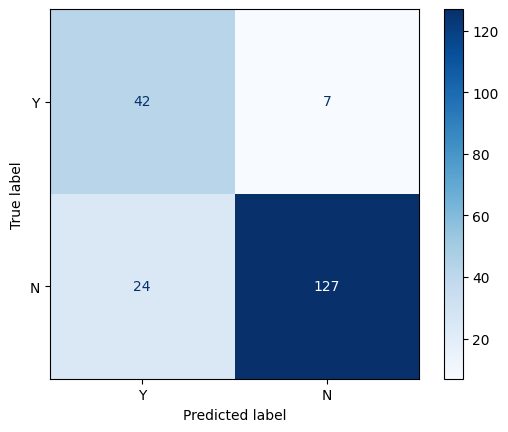

In [39]:
from imblearn.under_sampling import TomekLinks

k_comparison = []
for k_val in k_values:

    pipeline = imbpipeline([
        ("preprocessor", preprocessor),
        ("kn", SelectKBest(score_func=f_classif, k=k_val)),
        ("tomek", TomekLinks(
            n_jobs=-1,
            sampling_strategy="auto"
        )),
        ("model", DecisionTreeClassifier(
            splitter="random",
            min_samples_split=15,
            min_samples_leaf=10,
            max_depth=6,
            criterion="entropy",
            ccp_alpha=0.0001,
            random_state=42,
            class_weight="balanced"
        ))
    ])

    pipeline.fit(x_fit, y_fit)

    y_proba = pipeline.predict_proba(x_val)

    pos_idx = list(
        pipeline.named_steps["model"].classes_
    ).index(1)

    y_pos_proba = y_proba[:, pos_idx]

    for th in thresholds:

        y_pred = (y_pos_proba >= th).astype(int)

        f1 = f1_score(y_val, y_pred, pos_label=1, zero_division=0)
        prec = precision_score(y_val, y_pred, pos_label=1, zero_division=0)
        rec = recall_score(y_val, y_pred, pos_label=1, zero_division=0)

        k_comparison.append({
            "K": k_val,
            "Threshold": th,
            "Precision (Y)": prec,
            "Recall (Y)": rec,
            "F1-score (Y)": f1
        })

table = pd.DataFrame(k_comparison)

table = table.sort_values(
    "F1-score (Y)",
    ascending=False
)

display(
    table.style.highlight_max(
        subset=["Precision (Y)", "Recall (Y)", "F1-score (Y)"],
        color="green"
    )
)

best_row = table.iloc[0]

best_k = int(best_row["K"])
best_th = float(best_row["Threshold"])

print("Best K:", best_k)
print("Best Threshold:", best_th)
print("Validation F1:", best_row["F1-score (Y)"])

final_pipeline = imbpipeline([
    ("preprocessor", preprocessor),
    ("kn", SelectKBest(score_func=f_classif, k=best_k)),
    ("tomek", TomekLinks(
        n_jobs=-1,
        sampling_strategy="auto"
    )),
    ("model", DecisionTreeClassifier(
        splitter="random",
        min_samples_split=15,
        min_samples_leaf=10,
        max_depth=6,
        criterion="entropy",
        ccp_alpha=0.0001,
        random_state=42,
        class_weight="balanced"
    ))
])

final_pipeline.fit(x_train, y_train)

test_proba = final_pipeline.predict_proba(x_test)

pos_idx = list(
    final_pipeline.named_steps["model"].classes_
).index(1)

test_pred = (
    test_proba[:, pos_idx] >= best_th
).astype(int)

print("\n=== FINAL TEST RESULT ===")

print(classification_report(
    y_test,
    test_pred,
    target_names=["Non-Fraud", "Fraud"],
    zero_division=0
))

print("Final F1 (Fraud):",
      f1_score(y_test, test_pred, pos_label=1))

cm = confusion_matrix(y_test, test_pred, labels=[1, 0])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Y", "N"]
)

disp.plot(cmap="Blues")
plt.show()


In [40]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="prior", random_state=42)
dummy.fit(x_train, y_train)
y_pred = dummy.predict(x_test)
print(classification_report(y_test, y_pred))
print()

              precision    recall  f1-score   support

           0       0.76      1.00      0.86       151
           1       0.00      0.00      0.00        49

    accuracy                           0.76       200
   macro avg       0.38      0.50      0.43       200
weighted avg       0.57      0.76      0.65       200




/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
